

# Amazon Product Intelligence Platform
## Sentiment Analysis: Data Preprocessing and EDA

This notebook validates, cleans and explores the Amazon product and review dataset for sentiment analysis.



##Connect Google Drive and create working folders

In [2]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [RAW_DIR, PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project directory: {PROJECT_ROOT}")

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT


##Upload the two source files

In [3]:
from google.colab import files

uploaded = files.upload()

csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

xlsx_files = [
    name for name in uploaded
    if name.lower().endswith(".xlsx")
]

if len(csv_files) != 1:
    raise ValueError("Please upload exactly one product CSV file.")

if len(xlsx_files) != 1:
    raise ValueError("Please upload exactly one keyword Excel file.")

PRODUCT_DATA_PATH = RAW_DIR / "products_raw.csv"
KEYWORD_DATA_PATH = RAW_DIR / "search_keywords.xlsx"

PRODUCT_DATA_PATH.write_bytes(uploaded[csv_files[0]])
KEYWORD_DATA_PATH.write_bytes(uploaded[xlsx_files[0]])

print(f"Product dataset saved: {PRODUCT_DATA_PATH}")
print(f"Keyword file saved: {KEYWORD_DATA_PATH}")

Saving amazon_products.csv to amazon_products.csv
Saving Search Keyword Lists.xlsx to Search Keyword Lists.xlsx
Product dataset saved: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/raw/products_raw.csv
Keyword file saved: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/raw/search_keywords.xlsx


##Load the datasets

In [4]:
products_raw = pd.read_csv(
    PRODUCT_DATA_PATH,
    dtype=str,
    keep_default_na=False
)

keywords_raw = pd.read_excel(
    KEYWORD_DATA_PATH,
    dtype=str,
    keep_default_na=False
)

print("Product dataset shape:", products_raw.shape)
print("Keyword dataset shape:", keywords_raw.shape)

display(products_raw.head(3))
display(keywords_raw.head(5))

Product dataset shape: (1056, 12)
Keyword dataset shape: (28, 2)


,asin,keyword,product_url,title,price,brand,description,image_url,video_url,avg_rating,rating_count,reviews
0,B0H9LHWBDK,wireless earbuds,https://www.amazon.com/dp/B0H9LHWBDK,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",$18.99,Brand: XIAOWTEK,LED Power Display and 50H Playback: Dual digit...,https://m.media-amazon.com/images/I/61odQgshCW...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.8 out of 5 stars,(771),"[{""review_id"": ""R2CEXJGANFZ5NU"", ""reviewer_nam..."
1,B0HBWW3958,wireless earbuds,https://www.amazon.com/dp/B0HBWW3958,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",$19.98,Brand: Fhumsh,Smart LED Display & 50H Sport Headphones: The ...,https://m.media-amazon.com/images/I/61D5ZCSIym...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.3 out of 5 stars,(194),"[{""review_id"": ""R3N8ZPVF7TPV84"", ""reviewer_nam..."
2,B0H9RMD97X,wireless earbuds,https://www.amazon.com/dp/B0H9RMD97X,Air Pods for iPhone Bluetooth Wireless Ear Bud...,$13.99,Visit the Bioonis Store,【Balanced Hi-Fi Stereo Sound Earbuds】Experienc...,https://m.media-amazon.com/images/I/51wfpLrC24...,https://m.media-amazon.com/images/S/al-na-9d57...,4.3 out of 5 stars,N/A,[]


,SN,Search Keywords
0,1,wireless earbuds
1,2,gaming mouse
2,3,USB-C hub
3,4,mechanical keyboard
4,5,smartwatch


##Validate the required columns
This ensures that the uploaded dataset matches the schema our preprocessing pipeline expects.

In [5]:
REQUIRED_PRODUCT_COLUMNS = [
    "asin",
    "keyword",
    "product_url",
    "title",
    "price",
    "brand",
    "description",
    "image_url",
    "video_url",
    "avg_rating",
    "rating_count",
    "reviews"
]

missing_columns = sorted(
    set(REQUIRED_PRODUCT_COLUMNS) - set(products_raw.columns)
)

extra_columns = sorted(
    set(products_raw.columns) - set(REQUIRED_PRODUCT_COLUMNS)
)

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

if "Search Keywords" not in keywords_raw.columns:
    raise ValueError(
        "The keyword file must contain a 'Search Keywords' column."
    )

print("Schema validation successful.")
print("Missing columns:", missing_columns)
print("Additional columns:", extra_columns)

Schema validation successful.
Missing columns: []
Additional columns: []


##Generate the initial dataset summary

In [6]:
initial_summary = pd.DataFrame({
    "Metric": [
        "Product rows",
        "Unique ASINs",
        "Assigned keywords",
        "Collected keywords",
        "Rows with duplicated ASIN",
        "Extra ASIN rows to consolidate",
        "Empty review arrays"
    ],
    "Value": [
        len(products_raw),
        products_raw["asin"].nunique(),
        keywords_raw["Search Keywords"].nunique(),
        products_raw["keyword"].nunique(),
        products_raw.duplicated("asin", keep=False).sum(),
        len(products_raw) - products_raw["asin"].nunique(),
        products_raw["reviews"].str.strip().eq("[]").sum()
    ]
})

display(initial_summary)

,Metric,Value
0,Product rows,1056
1,Unique ASINs,981
2,Assigned keywords,28
3,Collected keywords,28
4,Rows with duplicated ASIN,150
5,Extra ASIN rows to consolidate,75
6,Empty review arrays,21


##Create an audit copy
We will inspect a separate copy so products_raw remains unchanged.

In [7]:
products_audit = products_raw.copy()

for column in products_audit.columns:
    products_audit[column] = (
        products_audit[column]
        .astype(str)
        .str.strip()
    )

MISSING_MARKERS = {
    "",
    "n/a",
    "na",
    "none",
    "null"
}

def missing_mask(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(MISSING_MARKERS)
    )

print("Audit copy created.")
print("Raw dataset remains unchanged:", products_raw.shape)

Audit copy created.
Raw dataset remains unchanged: (1056, 12)


##Measure missing product values
This produces the missing-value table required for data-quality analysis.

In [8]:
missing_report = pd.DataFrame({
    "column": products_audit.columns,
    "missing_count": [
        missing_mask(products_audit[column]).sum()
        for column in products_audit.columns
    ]
})

missing_report["missing_percentage"] = (
    missing_report["missing_count"]
    / len(products_audit)
    * 100
).round(2)

missing_report = missing_report.sort_values(
    "missing_count",
    ascending=False
).reset_index(drop=True)

display(missing_report)

,column,missing_count,missing_percentage
0,price,72,6.82
1,brand,30,2.84
2,video_url,13,1.23
3,rating_count,9,0.85
4,avg_rating,8,0.76
5,description,4,0.38
6,image_url,1,0.09
7,title,1,0.09
8,product_url,0,0.00
9,keyword,0,0.00


##Check keyword coverage and duplicate products
This verifies that every assigned keyword was collected and identifies repeated ASINs.

In [9]:
assigned_keywords = set(
    keywords_raw["Search Keywords"]
    .astype(str)
    .str.strip()
)

collected_keywords = set(
    products_audit["keyword"]
    .astype(str)
    .str.strip()
)

missing_keywords = sorted(
    assigned_keywords - collected_keywords
)

unexpected_keywords = sorted(
    collected_keywords - assigned_keywords
)

duplicate_asin_mask = products_audit.duplicated(
    subset=["asin"],
    keep=False
)

coverage_report = pd.DataFrame({
    "metric": [
        "Assigned keywords",
        "Collected keywords",
        "Missing assigned keywords",
        "Unexpected keywords",
        "Unique ASINs",
        "Duplicated ASINs",
        "Rows belonging to duplicated ASINs",
        "Exact duplicate rows"
    ],
    "value": [
        len(assigned_keywords),
        len(collected_keywords),
        len(missing_keywords),
        len(unexpected_keywords),
        products_audit["asin"].nunique(),
        products_audit.loc[
            duplicate_asin_mask, "asin"
        ].nunique(),
        duplicate_asin_mask.sum(),
        products_audit.duplicated(
            keep=False
        ).sum()
    ]
})

display(coverage_report)

print("Missing keywords:", missing_keywords)
print("Unexpected keywords:", unexpected_keywords)

,metric,value
0,Assigned keywords,28
1,Collected keywords,28
2,Missing assigned keywords,0
3,Unexpected keywords,0
4,Unique ASINs,981
5,Duplicated ASINs,75
6,Rows belonging to duplicated ASINs,150
7,Exact duplicate rows,58


Missing keywords: []
Unexpected keywords: []


##Audit numeric formats
This creates temporary numeric previews. It does not replace the original columns yet

In [10]:
price_preview = pd.to_numeric(
    products_audit["price"]
    .str.replace(",", "", regex=False)
    .str.extract(
        r"([0-9]+(?:\.[0-9]+)?)",
        expand=False
    ),
    errors="coerce"
)

avg_rating_preview = pd.to_numeric(
    products_audit["avg_rating"]
    .str.extract(
        r"([0-9]+(?:\.[0-9]+)?)",
        expand=False
    ),
    errors="coerce"
)

rating_count_text = (
    products_audit["rating_count"]
    .str.replace(r"[^0-9]", "", regex=True)
    .replace("", np.nan)
)

rating_count_preview = pd.to_numeric(
    rating_count_text,
    errors="coerce"
)

suspicious_price_mask = (
    products_audit["price"]
    .str.match(r"^\$\d{4,}$", na=False)
)

format_report = pd.DataFrame({
    "check": [
        "Unparseable prices",
        "Suspicious prices without decimals",
        "Unparseable average ratings",
        "Average ratings outside 1–5",
        "Unparseable rating counts"
    ],
    "count": [
        price_preview.isna().sum(),
        suspicious_price_mask.sum(),
        avg_rating_preview.isna().sum(),
        (
            (avg_rating_preview < 1)
            | (avg_rating_preview > 5)
        ).sum(),
        rating_count_preview.isna().sum()
    ]
})

display(format_report)

,check,count
0,Unparseable prices,72
1,Suspicious prices without decimals,5
2,Unparseable average ratings,8
3,Average ratings outside 1–5,0
4,Unparseable rating counts,9


In [11]:
suspicious_prices = products_audit.loc[
    suspicious_price_mask,
    [
        "asin",
        "keyword",
        "title",
        "price",
        "product_url"
    ]
]

display(suspicious_prices)

,asin,keyword,title,price,product_url
443,B09ZRN1N3Z,DSLR camera,"KODAK PIXPRO FZ55 16MP Compact Digital Camera,...",$10244,https://www.amazon.com/dp/B09ZRN1N3Z
446,B086TTTZR5,DSLR camera,Canon EOS RP Full-Frame Mirrorless Interchange...,$79900,https://www.amazon.com/dp/B086TTTZR5
447,B0BTTV6CT1,DSLR camera,Canon EOS R50 Mirrorless Camera RF-S18-45mm F4...,$79900,https://www.amazon.com/dp/B0BTTV6CT1
1005,B07TJXQ1TL,yamaha accoustic guitar,Washburn Bella Tono Vite S9V Studio Cutaway Ac...,$11999,https://www.amazon.com/dp/B07TJXQ1TL
1020,B084BZH9PG,yamaha accoustic guitar,Ibanez AEG70L Left-Handed Acoustic-Electric Gu...,$33867,https://www.amazon.com/dp/B084BZH9PG


##Validate the nested review JSON
This confirms whether every review cell is valid and whether review objects contain the expected fields.

In [12]:
REQUIRED_REVIEW_FIELDS = {
    "review_id",
    "reviewer_name",
    "headline",
    "review_text",
    "rating",
    "review_date"
}

invalid_json_rows = []
non_list_rows = []
invalid_review_items = []
review_missing_fields = {
    field: 0
    for field in REQUIRED_REVIEW_FIELDS
}

total_review_objects = 0
empty_review_arrays = 0

for row_index, raw_reviews in products_audit["reviews"].items():

    try:
        review_list = json.loads(raw_reviews)
    except (json.JSONDecodeError, TypeError):
        invalid_json_rows.append(row_index)
        continue

    if not isinstance(review_list, list):
        non_list_rows.append(row_index)
        continue

    if len(review_list) == 0:
        empty_review_arrays += 1

    for review_position, review in enumerate(review_list):

        if not isinstance(review, dict):
            invalid_review_items.append(
                (row_index, review_position)
            )
            continue

        total_review_objects += 1

        for field in REQUIRED_REVIEW_FIELDS:
            value = str(review.get(field, "")).strip()

            if value.lower() in MISSING_MARKERS:
                review_missing_fields[field] += 1

In [13]:
review_json_report = pd.DataFrame({
    "check": [
        "Total review objects",
        "Empty review arrays",
        "Invalid JSON cells",
        "Non-list review cells",
        "Invalid review items",
        "Missing review IDs",
        "Missing reviewer names",
        "Missing headlines",
        "Missing review text",
        "Missing review ratings",
        "Missing review dates"
    ],
    "count": [
        total_review_objects,
        empty_review_arrays,
        len(invalid_json_rows),
        len(non_list_rows),
        len(invalid_review_items),
        review_missing_fields["review_id"],
        review_missing_fields["reviewer_name"],
        review_missing_fields["headline"],
        review_missing_fields["review_text"],
        review_missing_fields["rating"],
        review_missing_fields["review_date"]
    ]
})

display(review_json_report)

,check,count
0,Total review objects,8183
1,Empty review arrays,21
2,Invalid JSON cells,0
3,Non-list review cells,0
4,Invalid review items,0
5,Missing review IDs,0
6,Missing reviewer names,0
7,Missing headlines,2
8,Missing review text,2
9,Missing review ratings,0


##Save the pre-cleaning quality report
This combines the important results into one CSV for documentation and client evidence.

In [14]:
missing_output = missing_report.copy()
missing_output.insert(0, "section", "missing_values")
missing_output = missing_output.rename(
    columns={"column": "check", "missing_count": "value"}
)

missing_output["details"] = (
    missing_output["missing_percentage"]
    .astype(str)
    + "%"
)

missing_output = missing_output[
    ["section", "check", "value", "details"]
]

coverage_output = coverage_report.copy()
coverage_output.insert(0, "section", "coverage_and_duplicates")
coverage_output["details"] = ""
coverage_output = coverage_output[
    ["section", "metric", "value", "details"]
].rename(columns={"metric": "check"})

format_output = format_report.copy()
format_output.insert(0, "section", "format_validation")
format_output["details"] = ""
format_output = format_output[
    ["section", "check", "count", "details"]
].rename(columns={"count": "value"})

review_output = review_json_report.copy()
review_output.insert(0, "section", "review_json_validation")
review_output["details"] = ""
review_output = review_output[
    ["section", "check", "count", "details"]
].rename(columns={"count": "value"})

quality_report = pd.concat(
    [
        missing_output,
        coverage_output,
        format_output,
        review_output
    ],
    ignore_index=True
)

QUALITY_REPORT_PATH = (
    REPORT_DIR
    / "data_quality_before_cleaning.csv"
)

quality_report.to_csv(
    QUALITY_REPORT_PATH,
    index=False
)

print(f"Quality report saved to: {QUALITY_REPORT_PATH}")

Quality report saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/data_quality_before_cleaning.csv


##**Interpretation**
### Data-quality interpretation

- All 28 assigned search keywords are present in the collected dataset.
- The nested review data is structurally consistent and contains no invalid JSON cells.
- Seventy-five ASINs are duplicated and must be consolidated into one product row per ASIN.
- Missing product values are limited and do not prevent sentiment-analysis development.
- Products with empty review arrays must remain in the product dataset but cannot be used for sentiment-model training.
- Five prices have suspicious formatting and will be flagged for manual verification instead of being automatically corrected.
- Review headlines and text contain very few missing values.
- The original raw dataset will remain unchanged; all transformations will be applied to a separate cleaned copy.

##Define missing-value and brand-cleaning functions
These functions provide consistent rules for identifying missing values and normalizing brand names.

In [15]:
import re

def is_missing_value(value):
    return (
        pd.isna(value)
        or str(value).strip().lower() in MISSING_MARKERS
    )


def clean_brand(value):
    if is_missing_value(value):
        return pd.NA

    brand = str(value).strip()

    brand = re.sub(
        r"^brand\s*:\s*",
        "",
        brand,
        flags=re.IGNORECASE
    )

    store_match = re.match(
        r"^visit the (.+?) store$",
        brand,
        flags=re.IGNORECASE
    )

    if store_match:
        brand = store_match.group(1)

    return brand.strip()

##Define the product-consolidation function
For each ASIN, this function:

Selects the most complete row.
* Fills missing values from its duplicate row.





* Combines reviews without repeating review_id.
* Preserves multiple video URLs.
* Records conflicting product information.

In [17]:
COMPLETENESS_FIELDS = [
    "title",
    "price",
    "brand",
    "description",
    "image_url",
    "video_url",
    "avg_rating",
    "rating_count"
]

CONFLICT_FIELDS = [
    "title",
    "price",
    "brand",
    "description",
    "image_url",
    "avg_rating",
    "rating_count"
]


def unique_valid_values(series):
    values = []

    for value in series:
        if not is_missing_value(value) and value not in values:
            values.append(value)

    return values


def consolidate_product(group):
    group = group.copy()

    completeness_scores = group[
        COMPLETENESS_FIELDS
    ].apply(
        lambda row: sum(
            not is_missing_value(value)
            for value in row
        ),
        axis=1
    )

    # Deterministically select the first row with the best score.
    base_row = group.loc[
        completeness_scores.idxmax()
    ].copy()

    # Fill missing base values from another available row.
    for column in COMPLETENESS_FIELDS:
        if is_missing_value(base_row[column]):
            available_values = unique_valid_values(
                group[column]
            )

            if available_values:
                base_row[column] = available_values[0]

    # Identify conflicting non-missing product information.
    conflicting_fields = []

    for column in CONFLICT_FIELDS:
        available_values = unique_valid_values(
            group[column]
        )

        if len(available_values) > 1:
            conflicting_fields.append(column)

    # Preserve every unique video URL.
    video_urls = unique_valid_values(
        group["video_url"]
    )

    base_row["video_url"] = (
        video_urls[0]
        if video_urls
        else pd.NA
    )

    base_row["video_urls"] = json.dumps(
        video_urls,
        ensure_ascii=False
    )

    # Combine reviews using review_id as the primary key.
    unique_reviews = {}

    for raw_reviews in group["reviews"]:
        review_list = json.loads(raw_reviews)

        for review in review_list:
            review_id = str(
                review.get("review_id", "")
            ).strip()

            if review_id:
                review_key = review_id
            else:
                review_key = json.dumps(
                    {
                        "headline": review.get("headline"),
                        "review_text": review.get("review_text"),
                        "rating": review.get("rating"),
                        "review_date": review.get("review_date")
                    },
                    sort_keys=True,
                    ensure_ascii=False
                )

            if review_key not in unique_reviews:
                unique_reviews[review_key] = review

    merged_reviews = list(unique_reviews.values())

    base_row["reviews"] = json.dumps(
        merged_reviews,
        ensure_ascii=False
    )

    base_row["source_row_count"] = len(group)
    base_row["duplicate_asin"] = len(group) > 1

    base_row["conflicting_fields"] = ", ".join(
        conflicting_fields
    )

    return base_row

##Consolidate the dataset by ASIN
This runs the function for every unique product

In [18]:
consolidated_rows = []

for asin, product_group in products_audit.groupby(
    "asin",
    sort=False
):
    consolidated_rows.append(
        consolidate_product(product_group)
    )

products_clean = pd.DataFrame(
    consolidated_rows
).reset_index(drop=True)

print("Raw product rows:", len(products_raw))
print("Clean product rows:", len(products_clean))
print("Unique clean ASINs:", products_clean["asin"].nunique())

Raw product rows: 1056
Clean product rows: 981
Unique clean ASINs: 981


##Normalize missing product values
We now convert textual missing markers such as N/A into proper null values.

In [19]:
PRODUCT_TEXT_FIELDS = [
    "title",
    "brand",
    "description",
    "image_url",
    "video_url",
    "avg_rating",
    "rating_count",
    "price"
]

for column in PRODUCT_TEXT_FIELDS:
    products_clean[column] = products_clean[column].apply(
        lambda value: (
            pd.NA
            if is_missing_value(value)
            else str(value).strip()
        )
    )

##Convert product fields into usable formats

We preserve the original values in *_raw columns before converting them.

Suspicious prices will become missing numeric values and receive a verification flag. We will not guess their correct prices.

In [20]:
products_clean["price_raw"] = products_clean["price"]
products_clean["avg_rating_raw"] = products_clean["avg_rating"]
products_clean["rating_count_raw"] = products_clean["rating_count"]


def parse_price(value):
    if is_missing_value(value):
        return np.nan

    text = str(value).strip()

    # Examples such as $79900 require manual verification.
    if re.match(r"^\$\d{4,}$", text):
        return np.nan

    cleaned = re.sub(
        r"[^0-9.]",
        "",
        text.replace(",", "")
    )

    return float(cleaned) if cleaned else np.nan


def parse_average_rating(value):
    if is_missing_value(value):
        return np.nan

    match = re.search(
        r"([0-9]+(?:\.[0-9]+)?)",
        str(value)
    )

    return float(match.group(1)) if match else np.nan


def parse_rating_count(value):
    if is_missing_value(value):
        return pd.NA

    digits = re.sub(
        r"[^0-9]",
        "",
        str(value)
    )

    return int(digits) if digits else pd.NA

In [21]:
products_clean["price_needs_verification"] = (
    products_clean["price_raw"]
    .astype("string")
    .str.match(r"^\$\d{4,}$", na=False)
)

products_clean["price"] = products_clean[
    "price_raw"
].apply(parse_price)

products_clean["currency"] = np.where(
    products_clean["price_raw"]
    .astype("string")
    .str.contains(r"\$", na=False),
    "USD",
    pd.NA
)

products_clean["avg_rating"] = products_clean[
    "avg_rating_raw"
].apply(parse_average_rating)

products_clean["rating_count"] = products_clean[
    "rating_count_raw"
].apply(parse_rating_count).astype("Int64")

products_clean["brand"] = products_clean[
    "brand"
].apply(clean_brand)

##Add category and review-availability fields

In [22]:
products_clean["category"] = products_clean["keyword"]

products_clean["review_count_collected"] = (
    products_clean["reviews"]
    .apply(lambda value: len(json.loads(value)))
)

products_clean["has_reviews"] = (
    products_clean["review_count_collected"] > 0
)

products_clean["review_collection_status"] = np.where(
    products_clean["has_reviews"],
    "reviews_collected",
    "unknown_empty"
)

products_clean["needs_manual_verification"] = (
    products_clean["price_needs_verification"]
    | products_clean["conflicting_fields"].ne("")
)

##Arrange the clean columns

This makes the saved dataset easier to understand and use later.

In [23]:
PRODUCT_OUTPUT_COLUMNS = [
    "asin",
    "keyword",
    "category",
    "product_url",
    "title",
    "price",
    "price_raw",
    "currency",
    "price_needs_verification",
    "brand",
    "description",
    "image_url",
    "video_url",
    "video_urls",
    "avg_rating",
    "avg_rating_raw",
    "rating_count",
    "rating_count_raw",
    "reviews",
    "review_count_collected",
    "has_reviews",
    "review_collection_status",
    "source_row_count",
    "duplicate_asin",
    "conflicting_fields",
    "needs_manual_verification"
]

products_clean = products_clean[
    PRODUCT_OUTPUT_COLUMNS
]

##Validate the cleaned product dataset
These checks stop the notebook if product deduplication failed.

In [24]:
expected_unique_products = (
    products_raw["asin"].nunique()
)

assert (
    len(products_clean)
    == expected_unique_products
)
assert products_clean["asin"].is_unique
assert products_clean["asin"].notna().all()

assert products_clean["reviews"].apply(
    lambda value: isinstance(json.loads(value), list)
).all()

product_cleaning_summary = pd.DataFrame({
    "metric": [
        "Raw product rows",
        "Clean unique products",
        "Rows consolidated",
        "Products with reviews",
        "Products with empty reviews",
        "Product-review associations",
        "Suspicious prices",
        "Products with conflicting fields"
    ],
    "value": [
        len(products_raw),
        len(products_clean),
        len(products_raw) - len(products_clean),
        products_clean["has_reviews"].sum(),
        (~products_clean["has_reviews"]).sum(),
        products_clean["review_count_collected"].sum(),
        products_clean["price_needs_verification"].sum(),
        products_clean["conflicting_fields"].ne("").sum()
    ]
})

display(product_cleaning_summary)

,metric,value
0,Raw product rows,1056
1,Clean unique products,981
2,Rows consolidated,75
3,Products with reviews,961
4,Products with empty reviews,20
5,Product-review associations,7595
6,Suspicious prices,5
7,Products with conflicting fields,4


##Save the clean product dataset

In [25]:
PRODUCTS_CLEAN_PATH = (
    PROCESSED_DIR
    / "products_clean.csv"
)

products_clean.to_csv(
    PRODUCTS_CLEAN_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(f"Clean product dataset saved to: {PRODUCTS_CLEAN_PATH}")

Clean product dataset saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/products_clean.csv


### Product-cleaning interpretation

- The original 1,056 rows were consolidated into 981 unique products.
- Duplicate ASINs were resolved by selecting the most complete record and combining their unique reviews.
- No collected reviews were removed during product consolidation.
- Products without reviews were retained for product browsing but will not be included in sentiment-model training.
- Conflicting product values were flagged for verification rather than silently overwritten.
- Suspicious prices were preserved in `price_raw` but excluded from the numeric `price` field until they can be verified.
- The search keyword was retained as the category for category-level sentiment reporting.

##Define lightweight text cleaning
Sentiment text should not be aggressively cleaned. We will normalize HTML, Unicode and unnecessary whitespace while preserving capitalization, negation, punctuation and emojis.

In [26]:
import hashlib
import html
import unicodedata


def normalize_review_text(value):
    if is_missing_value(value):
        return pd.NA

    text = html.unescape(str(value))
    text = re.sub(r"<[^>]+>", " ", text)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip() or pd.NA


def combine_review_text(headline, review_text):
    parts = []

    if not is_missing_value(headline):
        parts.append(str(headline).strip())

    if not is_missing_value(review_text):
        parts.append(str(review_text).strip())

    return " ".join(parts).strip() or pd.NA

##Define rating, date and fallback-ID functions
The dataset currently has valid review IDs, but the fallback function makes the pipeline safer for future data.

In [27]:
def parse_review_rating(value):
    if is_missing_value(value):
        return np.nan

    match = re.search(
        r"([0-9]+(?:\.[0-9]+)?)",
        str(value)
    )

    return float(match.group(1)) if match else np.nan


def parse_review_date(value):
    if is_missing_value(value):
        return pd.NaT

    date_text = re.sub(
        r"^Reviewed in .+? on ",
        "",
        str(value).strip()
    )

    return pd.to_datetime(
        date_text,
        errors="coerce"
    )


def create_fallback_review_id(asin, review):
    content = "|".join([
        str(asin),
        str(review.get("headline", "")),
        str(review.get("review_text", "")),
        str(review.get("rating", "")),
        str(review.get("review_date", ""))
    ])

    fingerprint = hashlib.sha256(
        content.encode("utf-8")
    ).hexdigest()[:16]

    return f"generated_{fingerprint}"

##Expand the nested reviews
Every product stays in products_clean, but only products with reviews produce rows here.

In [28]:
review_rows = []

for product in products_clean.itertuples(index=False):
    product_reviews = json.loads(product.reviews)

    for review in product_reviews:
        original_review_id = str(
            review.get("review_id", "")
        ).strip()

        review_id_generated = not original_review_id

        review_id = (
            original_review_id
            if original_review_id
            else create_fallback_review_id(
                product.asin,
                review
            )
        )

        headline = normalize_review_text(
            review.get("headline")
        )

        review_text = normalize_review_text(
            review.get("review_text")
        )

        model_text = combine_review_text(
            headline,
            review_text
        )

        review_rows.append({
            "asin": product.asin,
            "keyword": product.keyword,
            "category": product.category,
            "product_title": product.title,
            "product_url": product.product_url,
            "review_id": review_id,
            "review_id_generated": review_id_generated,
            "reviewer_name": normalize_review_text(
                review.get("reviewer_name")
            ),
            "headline": headline,
            "review_text_raw": review.get(
                "review_text"
            ),
            "review_text_clean": review_text,
            "model_text": model_text,
            "review_rating_raw": review.get(
                "rating"
            ),
            "review_rating": parse_review_rating(
                review.get("rating")
            ),
            "review_date_raw": review.get(
                "review_date"
            ),
            "review_date": parse_review_date(
                review.get("review_date")
            )
        })

reviews_clean = pd.DataFrame(review_rows)

print("Expanded review rows:", len(reviews_clean))
display(reviews_clean.head(3))

Expanded review rows: 7595


,asin,keyword,category,product_title,product_url,review_id,review_id_generated,reviewer_name,headline,review_text_raw,review_text_clean,model_text,review_rating_raw,review_rating,review_date_raw,review_date
0,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R2CEXJGANFZ5NU,False,diamela,Great earbuds for the price,I’m really happy with these earbuds. The sound...,I’m really happy with these earbuds. The sound...,Great earbuds for the price I’m really happy w...,5.0 out of 5 stars,5.0,"Reviewed in the United States on August 18, 2026",2026-08-18
1,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R5VDNB3U3J2X2,False,Shakira Peñas,Recommended,These wireless earbuds have excellent sound qu...,These wireless earbuds have excellent sound qu...,Recommended These wireless earbuds have excell...,5.0 out of 5 stars,5.0,"Reviewed in the United States on August 23, 2026",2026-08-23
2,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R1SXLCYBW5CNNX,False,Yuriko Matsumoto,Audífonos,I’m really impressed with these wireless earbu...,I’m really impressed with these wireless earbu...,Audífonos I’m really impressed with these wire...,5.0 out of 5 stars,5.0,"Reviewed in the United States on August 24, 2026",2026-08-24


##Remove duplicates within the same product
A review is duplicated within a product only when the same asin and review_id appear more than once.

We never deduplicate using reviewer_name

In [29]:
reviews_before_deduplication = len(reviews_clean)

within_product_duplicate_mask = (
    reviews_clean.duplicated(
        subset=["asin", "review_id"],
        keep=False
    )
)

within_product_duplicate_rows = (
    within_product_duplicate_mask.sum()
)

reviews_clean = (
    reviews_clean
    .drop_duplicates(
        subset=["asin", "review_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

removed_review_rows = (
    reviews_before_deduplication
    - len(reviews_clean)
)

print(
    "Duplicate rows detected:",
    within_product_duplicate_rows
)

print(
    "Duplicate copies removed:",
    removed_review_rows
)

Duplicate rows detected: 0
Duplicate copies removed: 0


##Detect reviews shared across ASINs
This does not remove anything. It adds information showing how many ASINs contain each review

In [30]:
review_sharing = (
    reviews_clean
    .groupby("review_id")
    .agg(
        asin_count_for_review=(
            "asin",
            "nunique"
        ),
        shared_asins=(
            "asin",
            lambda values: json.dumps(
                sorted(set(values))
            )
        ),
        text_versions=(
            "model_text",
            "nunique"
        )
    )
    .reset_index()
)

review_sharing["shared_across_asins"] = (
    review_sharing["asin_count_for_review"] > 1
)

review_sharing["review_content_conflict"] = (
    review_sharing["text_versions"] > 1
)

reviews_clean = reviews_clean.merge(
    review_sharing,
    on="review_id",
    how="left",
    validate="many_to_one"
)

In [31]:
sharing_summary = pd.DataFrame({
    "metric": [
        "Review rows",
        "Unique review IDs",
        "Review IDs shared across ASINs",
        "Rows belonging to shared reviews",
        "Review IDs with conflicting text"
    ],
    "value": [
        len(reviews_clean),
        reviews_clean["review_id"].nunique(),
        review_sharing[
            "shared_across_asins"
        ].sum(),
        reviews_clean[
            "shared_across_asins"
        ].sum(),
        review_sharing[
            "review_content_conflict"
        ].sum()
    ]
})

display(sharing_summary)

,metric,value
0,Review rows,7595
1,Unique review IDs,6486
2,Review IDs shared across ASINs,557
3,Rows belonging to shared reviews,1666
4,Review IDs with conflicting text,0


##Add model-readiness fields

This identifies reviews that can be used for sentiment analysis and measures their length



In [32]:
reviews_clean["usable_for_sentiment"] = (
    reviews_clean["model_text"]
    .notna()
    & reviews_clean["model_text"]
    .astype(str)
    .str.strip()
    .ne("")
)

reviews_clean["text_character_count"] = (
    reviews_clean["model_text"]
    .fillna("")
    .astype(str)
    .str.len()
)

reviews_clean["text_word_count"] = (
    reviews_clean["model_text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

reviews_clean["review_date"] = (
    pd.to_datetime(
        reviews_clean["review_date"],
        errors="coerce"
    )
    .dt.strftime("%Y-%m-%d")
)

In [33]:
review_cleaning_summary = pd.DataFrame({
    "metric": [
        "Product-review associations",
        "Unique review IDs",
        "Products represented",
        "Usable sentiment rows",
        "Unusable sentiment rows",
        "Unparseable ratings",
        "Unparseable dates",
        "Reviews longer than 500 words",
        "Keyword-level unique reviews"
    ],
    "value": [
        len(reviews_clean),
        reviews_clean["review_id"].nunique(),
        reviews_clean["asin"].nunique(),
        reviews_clean["usable_for_sentiment"].sum(),
        (~reviews_clean["usable_for_sentiment"]).sum(),
        reviews_clean["review_rating"].isna().sum(),
        reviews_clean["review_date"].isna().sum(),
        (
            reviews_clean["text_word_count"] > 500
        ).sum(),
        len(
            reviews_clean.drop_duplicates(
                ["category", "review_id"]
            )
        )
    ]
})

display(review_cleaning_summary)

,metric,value
0,Product-review associations,7595
1,Unique review IDs,6486
2,Products represented,961
3,Usable sentiment rows,7595
4,Unusable sentiment rows,0
5,Unparseable ratings,0
6,Unparseable dates,0
7,Reviews longer than 500 words,236
8,Keyword-level unique reviews,6486


In [34]:
REVIEW_OUTPUT_COLUMNS = [
    "asin",
    "keyword",
    "category",
    "product_title",
    "product_url",
    "review_id",
    "review_id_generated",
    "reviewer_name",
    "headline",
    "review_text_raw",
    "review_text_clean",
    "model_text",
    "review_rating",
    "review_rating_raw",
    "review_date",
    "review_date_raw",
    "usable_for_sentiment",
    "text_character_count",
    "text_word_count",
    "shared_across_asins",
    "asin_count_for_review",
    "shared_asins",
    "review_content_conflict"
]

reviews_clean = reviews_clean[
    REVIEW_OUTPUT_COLUMNS
]

REVIEWS_CLEAN_PATH = (
    PROCESSED_DIR
    / "reviews_clean.csv"
)

reviews_clean.to_csv(
    REVIEWS_CLEAN_PATH,
    index=False,
    encoding="utf-8-sig"
)

REVIEW_SUMMARY_PATH = (
    REPORT_DIR
    / "review_cleaning_summary.csv"
)

review_cleaning_summary.to_csv(
    REVIEW_SUMMARY_PATH,
    index=False
)

print(f"Clean reviews saved to: {REVIEWS_CLEAN_PATH}")
print(f"Review summary saved to: {REVIEW_SUMMARY_PATH}")

Clean reviews saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_clean.csv
Review summary saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/review_cleaning_summary.csv


### Review-cleaning interpretation

- The nested product reviews were expanded into 7,595 product-review associations.
- Review IDs were used for deduplication; reviewer names were never used as unique identifiers.
- No duplicate review IDs were found within individual products after product consolidation.
- Some reviews appear under multiple ASINs, which is consistent with Amazon sharing reviews between product variants.
- Shared reviews are retained for product-level analysis but will be counted only once for keyword-level summaries and model training.
- All available review records contain usable sentiment text after combining the headline and review body.
- Text cleaning preserved negation, punctuation, capitalization and emojis because these may carry sentiment.
- The cleaned review dataset is now ready for exploratory data analysis.

##Import visualization packages

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep"
)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.titlesize": 14
})

##Display the main dataset statistics
These values provide a high-level overview of the data available for sentiment analysis.

In [36]:
dataset_overview = pd.DataFrame({
    "metric": [
        "Unique products",
        "Keywords/categories",
        "Product-review associations",
        "Unique review IDs",
        "Products with reviews",
        "Products without reviews",
        "Usable sentiment rows"
    ],
    "value": [
        products_clean["asin"].nunique(),
        products_clean["category"].nunique(),
        len(reviews_clean),
        reviews_clean["review_id"].nunique(),
        products_clean["has_reviews"].sum(),
        (~products_clean["has_reviews"]).sum(),
        reviews_clean["usable_for_sentiment"].sum()
    ]
})

display(dataset_overview)

,metric,value
0,Unique products,981
1,Keywords/categories,28
2,Product-review associations,7595
3,Unique review IDs,6486
4,Products with reviews,961
5,Products without reviews,20
6,Usable sentiment rows,7595


##Calculate coverage for every keyword
For category-level statistics, shared Amazon variant reviews are counted only once within each keyword.

In [37]:
product_coverage = (
    products_clean
    .groupby("category")
    .agg(
        product_count=(
            "asin",
            "nunique"
        ),
        products_with_reviews=(
            "has_reviews",
            "sum"
        ),
        collected_review_associations=(
            "review_count_collected",
            "sum"
        )
    )
)

unique_category_reviews = (
    reviews_clean[
        reviews_clean["usable_for_sentiment"]
    ]
    .drop_duplicates(
        subset=["category", "review_id"]
    )
    .groupby("category")
    .size()
    .rename("unique_review_count")
)

keyword_coverage = (
    product_coverage
    .join(unique_category_reviews)
    .fillna({"unique_review_count": 0})
    .reset_index()
)

keyword_coverage["unique_review_count"] = (
    keyword_coverage["unique_review_count"]
    .astype(int)
)

keyword_coverage["products_without_reviews"] = (
    keyword_coverage["product_count"]
    - keyword_coverage["products_with_reviews"]
)

keyword_coverage["review_coverage_percentage"] = (
    keyword_coverage["products_with_reviews"]
    / keyword_coverage["product_count"]
    * 100
).round(2)

keyword_coverage = keyword_coverage.sort_values(
    "product_count",
    ascending=False
).reset_index(drop=True)

display(keyword_coverage)

,category,product_count,products_with_reviews,collected_review_associations,unique_review_count,products_without_reviews,review_coverage_percentage
0,sneakers,60,60,480,448,0,100.00
1,coffee maker,58,58,460,300,0,100.00
2,water bottle,58,58,464,344,0,100.00
3,sunglasses,57,56,446,422,1,98.25
4,t-shirt,57,57,456,336,0,100.00
5,yamaha accoustic guitar,56,55,421,389,1,98.21
6,notebook journal,55,55,440,368,0,100.00
7,gaming chair,55,55,433,353,0,100.00
8,electric toothbrush,54,53,416,315,1,98.15
9,kitchen knife set,54,50,400,352,4,92.59


In [38]:
KEYWORD_COVERAGE_PATH = (
    REPORT_DIR
    / "keyword_coverage.csv"
)

keyword_coverage.to_csv(
    KEYWORD_COVERAGE_PATH,
    index=False
)

print(f"Coverage table saved to: {KEYWORD_COVERAGE_PATH}")

Coverage table saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/keyword_coverage.csv


##Visualize products and reviews by keyword
The first chart shows product coverage. The second shows unique review coverage without double-counting reviews shared across ASINs.

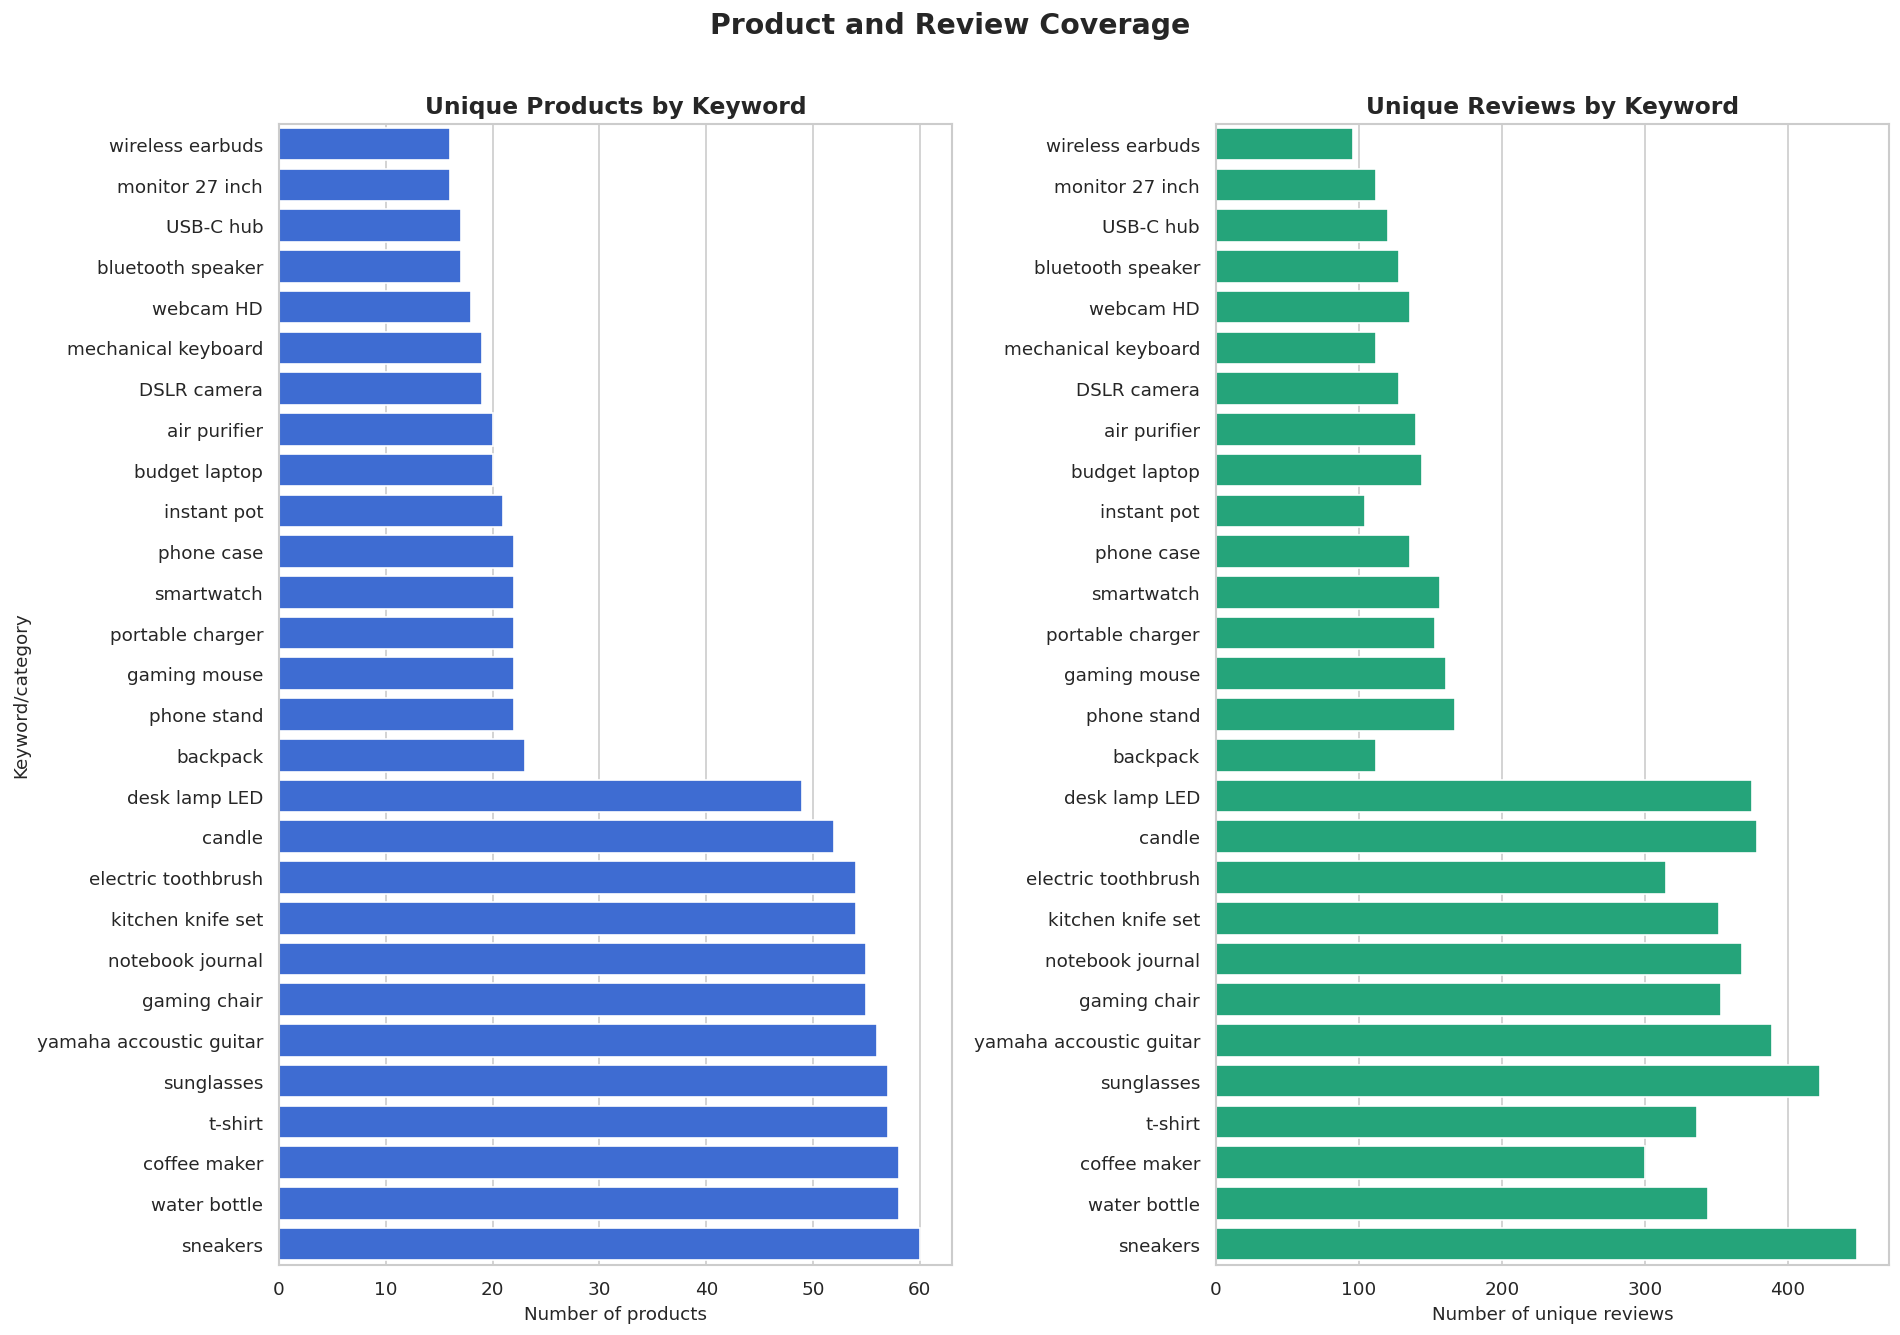

In [39]:
coverage_plot = keyword_coverage.sort_values(
    "product_count",
    ascending=True
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 11)
)

sns.barplot(
    data=coverage_plot,
    x="product_count",
    y="category",
    color="#2563EB",
    ax=axes[0]
)

axes[0].set_title("Unique Products by Keyword")
axes[0].set_xlabel("Number of products")
axes[0].set_ylabel("Keyword/category")

sns.barplot(
    data=coverage_plot,
    x="unique_review_count",
    y="category",
    color="#10B981",
    ax=axes[1]
)

axes[1].set_title("Unique Reviews by Keyword")
axes[1].set_xlabel("Number of unique reviews")
axes[1].set_ylabel("")

fig.suptitle(
    "Product and Review Coverage",
    fontsize=17,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

coverage_figure_path = (
    FIGURE_DIR
    / "keyword_product_review_coverage.png"
)

plt.savefig(
    coverage_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##Analyze reviews collected per product

The requirement asks for reviews visible on the first review page. This chart helps confirm how many reviews were captured for each product.

In [40]:
reviews_per_product = (
    products_clean["review_count_collected"]
    .value_counts()
    .sort_index()
    .rename_axis("reviews_collected")
    .reset_index(name="product_count")
)

display(reviews_per_product)

,reviews_collected,product_count
0,0,20
1,1,4
2,2,2
3,3,2
4,4,7
5,5,1
6,6,5
7,7,2
8,8,938


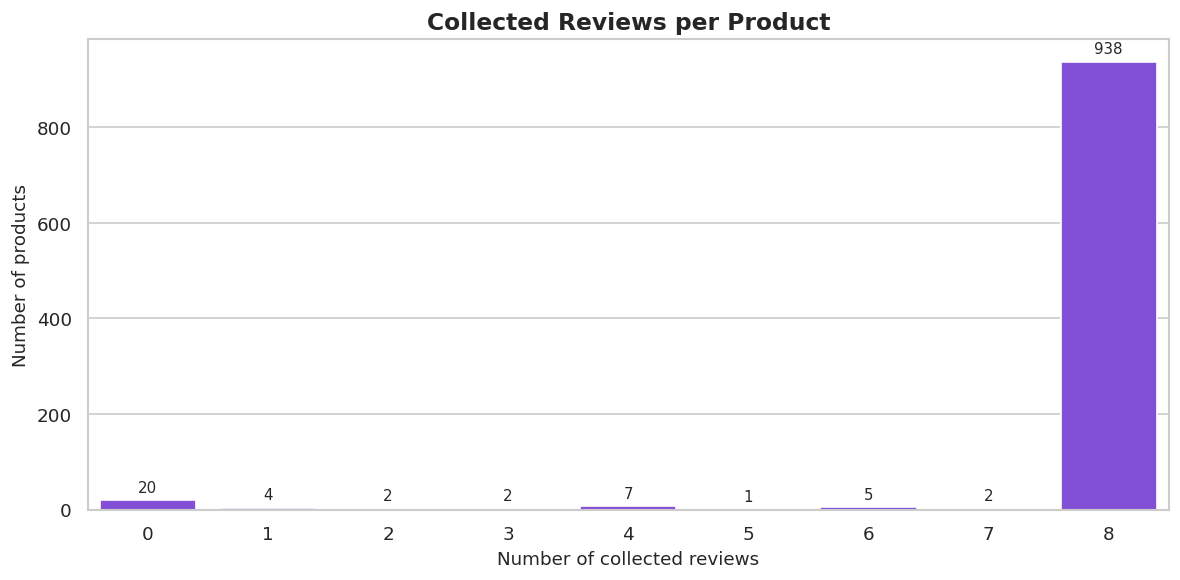

In [41]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=reviews_per_product,
    x="reviews_collected",
    y="product_count",
    color="#7C3AED"
)

ax.set_title("Collected Reviews per Product")
ax.set_xlabel("Number of collected reviews")
ax.set_ylabel("Number of products")

for container in ax.containers:
    ax.bar_label(
        container,
        padding=3,
        fontsize=9
    )

plt.tight_layout()

review_coverage_figure_path = (
    FIGURE_DIR
    / "reviews_per_product.png"
)

plt.savefig(
    review_coverage_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##Analyze missing values after cleaning

This checks the fields relevant to product display and sentiment reporting.

In [42]:
PRODUCT_AUDIT_COLUMNS = [
    "title",
    "price",
    "brand",
    "description",
    "image_url",
    "video_url",
    "avg_rating",
    "rating_count",
    "reviews"
]

missing_after_cleaning = pd.DataFrame({
    "field": PRODUCT_AUDIT_COLUMNS,
    "missing_count": [
        products_clean[column].isna().sum()
        for column in PRODUCT_AUDIT_COLUMNS
    ]
})

missing_after_cleaning["missing_percentage"] = (
    missing_after_cleaning["missing_count"]
    / len(products_clean)
    * 100
).round(2)

missing_after_cleaning = (
    missing_after_cleaning
    .sort_values(
        "missing_percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

display(missing_after_cleaning)

,field,missing_count,missing_percentage
0,price,73,7.44
1,brand,29,2.96
2,video_url,11,1.12
3,rating_count,8,0.82
4,avg_rating,7,0.71
5,description,3,0.31
6,title,0,0.00
7,image_url,0,0.00
8,reviews,0,0.00


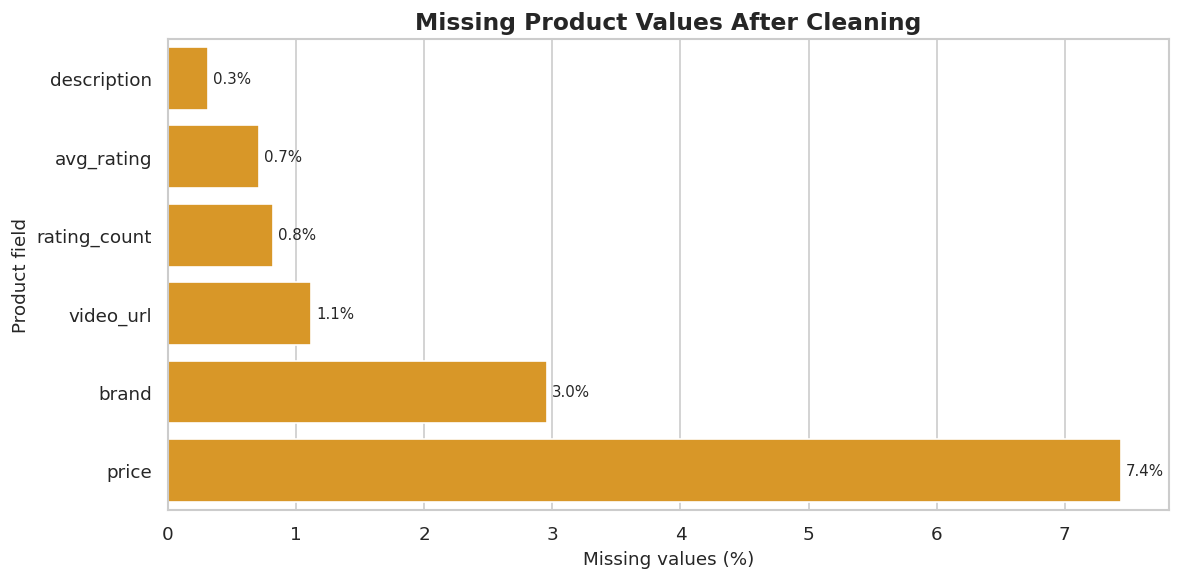

In [43]:
MISSING_REPORT_PATH = (
    REPORT_DIR
    / "missing_values_after_cleaning.csv"
)

missing_after_cleaning.to_csv(
    MISSING_REPORT_PATH,
    index=False
)

missing_plot = missing_after_cleaning[
    missing_after_cleaning["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=True
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=missing_plot,
    x="missing_percentage",
    y="field",
    color="#F59E0B"
)

ax.set_title("Missing Product Values After Cleaning")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Product field")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

missing_figure_path = (
    FIGURE_DIR
    / "missing_values_after_cleaning.png"
)

plt.savefig(
    missing_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Coverage and data-quality interpretation

- All 28 assigned keywords are represented in the cleaned dataset.
- The dataset contains 981 unique products and 6,486 unique collected reviews.
- Product coverage varies across keywords, ranging from approximately 16 to 60 unique products.
- Unique review coverage also varies across keywords, ranging from approximately 96 to 448 reviews.
- This uneven coverage means that keyword-aware stratification should be considered when preparing manual validation samples.
- Most products contain eight collected reviews, which is consistent with collecting the reviews visible on the first review page.
- Twenty products have no collected reviews. They remain available for product browsing but cannot contribute to sentiment analysis.
- Shared Amazon variant reviews are retained for product-level analysis but counted only once in keyword-level summaries.
- Remaining missing product fields do not prevent sentiment training because all expanded review rows contain usable model text.

##Create the unique-review EDA dataset
This dataset is temporary and does not change reviews_clean.

In [44]:
reviews_eda = (
    reviews_clean[
        reviews_clean["usable_for_sentiment"]
    ]
    .drop_duplicates(
        subset=["review_id"],
        keep="first"
    )
    .copy()
    .reset_index(drop=True)
)

reviews_eda["review_rating"] = pd.to_numeric(
    reviews_eda["review_rating"],
    errors="coerce"
)

reviews_eda["review_date_parsed"] = pd.to_datetime(
    reviews_eda["review_date"],
    errors="coerce"
)

print("Unique reviews used for EDA:", len(reviews_eda))

Unique reviews used for EDA: 6486


##Analyze review-rating distribution
Review ratings are not the final sentiment labels. However, their distribution helps us understand likely class imbalance.

In [45]:
rating_distribution = (
    reviews_eda["review_rating"]
    .value_counts()
    .sort_index()
    .rename_axis("review_rating")
    .reset_index(name="review_count")
)

rating_distribution["percentage"] = (
    rating_distribution["review_count"]
    / rating_distribution["review_count"].sum()
    * 100
).round(2)

display(rating_distribution)

,review_rating,review_count,percentage
0,1.0,198,3.05
1,2.0,35,0.54
2,3.0,278,4.29
3,4.0,857,13.21
4,5.0,5118,78.91


In [46]:
rating_distribution.to_csv(
    REPORT_DIR / "rating_distribution.csv",
    index=False
)

##Analyze review-text lengths

This determines how much text the sentiment model must process and whether long reviews require special handling.



In [47]:
text_length_summary = pd.DataFrame({
    "metric": [
        "Minimum words",
        "Median words",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "99th percentile",
        "Maximum words",
        "Reviews above 500 words"
    ],
    "value": [
        reviews_eda["text_word_count"].min(),
        reviews_eda["text_word_count"].median(),
        reviews_eda["text_word_count"].quantile(0.75),
        reviews_eda["text_word_count"].quantile(0.90),
        reviews_eda["text_word_count"].quantile(0.95),
        reviews_eda["text_word_count"].quantile(0.99),
        reviews_eda["text_word_count"].max(),
        (
            reviews_eda["text_word_count"] > 500
        ).sum()
    ]
})

text_length_summary["value"] = (
    text_length_summary["value"].round(2)
)

display(text_length_summary)

,metric,value
0,Minimum words,1.00
1,Median words,71.00
2,75th percentile,148.75
3,90th percentile,281.00
4,95th percentile,418.00
5,99th percentile,764.15
6,Maximum words,2195.00
7,Reviews above 500 words,211.00


In [48]:
LENGTH_LABELS = [
    "1–50",
    "51–100",
    "101–250",
    "251–500",
    "Above 500"
]

reviews_eda["text_length_group"] = pd.cut(
    reviews_eda["text_word_count"],
    bins=[0, 50, 100, 250, 500, np.inf],
    labels=LENGTH_LABELS,
    include_lowest=True
)

text_length_distribution = (
    reviews_eda["text_length_group"]
    .value_counts()
    .reindex(LENGTH_LABELS, fill_value=0)
    .rename_axis("word_range")
    .reset_index(name="review_count")
)

display(text_length_distribution)

,word_range,review_count
0,1–50,2447
1,51–100,1591
2,101–250,1681
3,251–500,556
4,Above 500,211


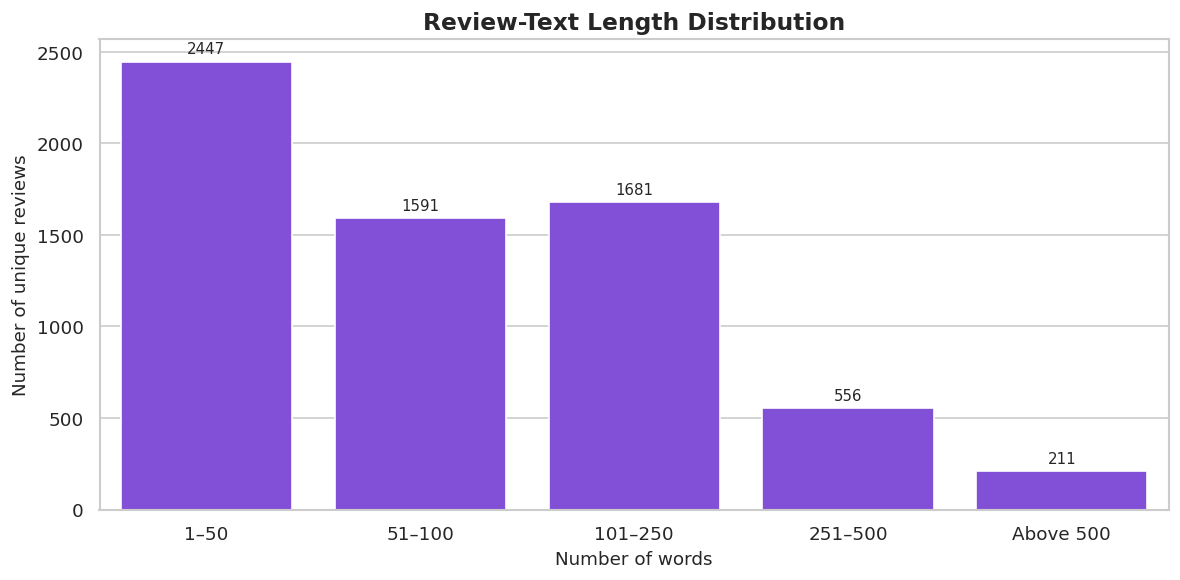

In [49]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=text_length_distribution,
    x="word_range",
    y="review_count",
    color="#7C3AED"
)

ax.set_title("Review-Text Length Distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of unique reviews")

for container in ax.containers:
    ax.bar_label(
        container,
        padding=3,
        fontsize=9
    )

plt.tight_layout()

text_length_figure_path = (
    FIGURE_DIR
    / "review_text_length_distribution.png"
)

plt.savefig(
    text_length_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
text_length_summary.to_csv(
    REPORT_DIR / "text_length_summary.csv",
    index=False
)

text_length_distribution.to_csv(
    REPORT_DIR / "text_length_distribution.csv",
    index=False
)

##Analyze review dates
This establishes the historical range and freshness of the collected reviews

In [51]:
review_year_distribution = (
    reviews_eda
    .dropna(subset=["review_date_parsed"])
    .assign(
        review_year=lambda data:
        data["review_date_parsed"].dt.year
    )
    .groupby("review_year")
    .size()
    .reset_index(name="review_count")
)

display(review_year_distribution.tail(10))

,review_year,review_count
11,2017,17
12,2018,19
13,2019,18
14,2020,29
15,2021,43
16,2022,50
17,2023,108
18,2024,171
19,2025,566
20,2026,5400


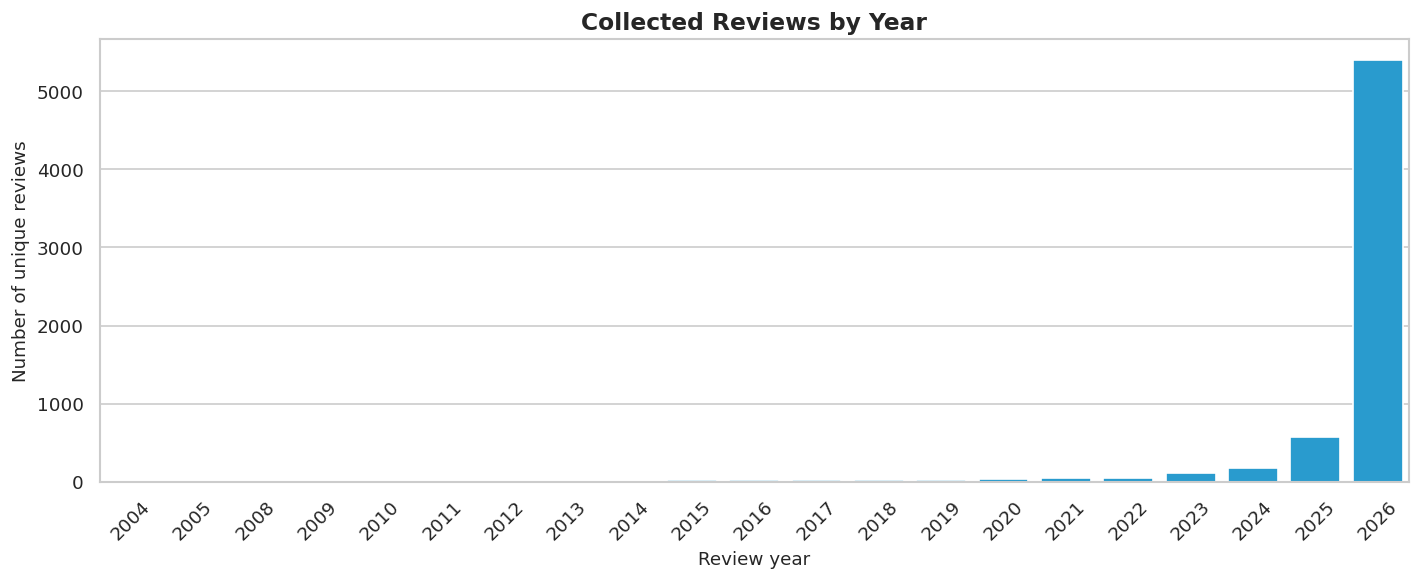

In [52]:
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    data=review_year_distribution,
    x="review_year",
    y="review_count",
    color="#0EA5E9"
)

ax.set_title("Collected Reviews by Year")
ax.set_xlabel("Review year")
ax.set_ylabel("Number of unique reviews")

plt.xticks(rotation=45)
plt.tight_layout()

date_figure_path = (
    FIGURE_DIR
    / "reviews_by_year.png"
)

plt.savefig(
    date_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
review_year_distribution.to_csv(
    REPORT_DIR / "review_year_distribution.csv",
    index=False
)

### Sentiment-oriented EDA interpretation

- Five-star reviews represent approximately 78.9% of the unique review dataset.
- The rating-based proxy indicates that approximately 92% of reviews may express positive sentiment.
- This proxy is not used as the final label because review ratings and written sentiment can disagree.
- The expected class imbalance means accuracy alone would be misleading. Macro-F1, per-class recall and class-weighted training should be used during model comparison.
- Model-training and manual-validation samples must be stratified so neutral and negative reviews are adequately represented.
- The median review contains approximately 71 words, while some reviews contain more than 2,000 words.
- Approximately 3.3% of unique reviews contain more than 500 words.
- The RoBERTa labeling pipeline must therefore use tokenizer-aware truncation or controlled chunking for long reviews.
- Review dates range from 2004 to August 2026, with most collected reviews coming from 2026. This indicates that the dataset contains substantial recent customer feedback.
- Final pseudo-labels will be generated from review text using CardiffNLP RoBERTa.

##Validate product integrity

These checks confirm that the product dataset follows the client’s one-row-per-product requirement

In [55]:
product_checks = {
    "Product ASINs are unique":
        products_clean["asin"].is_unique,

    "Every product has an ASIN":
        products_clean["asin"].notna().all(),

    "Every product has a keyword/category":
        products_clean["category"].notna().all(),

    "Every product has a product URL":
        products_clean["product_url"].notna().all(),

    "Every reviews field contains valid JSON":
        products_clean["reviews"].apply(
            lambda value:
            isinstance(json.loads(value), list)
        ).all()
}

for check, passed in product_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'}: {check}"
    )

assert all(product_checks.values())

PASS: Product ASINs are unique
PASS: Every product has an ASIN
PASS: Every product has a keyword/category
PASS: Every product has a product URL
PASS: Every reviews field contains valid JSON


##Validate review integrity

These checks confirm that the review dataset has no invalid product relationships or duplicated product-review combinations.

In [56]:
valid_product_asins = set(
    products_clean["asin"]
)

review_asins = set(
    reviews_clean["asin"]
)

orphan_review_asins = (
    review_asins - valid_product_asins
)

duplicate_product_reviews = (
    reviews_clean.duplicated(
        subset=["asin", "review_id"]
    ).sum()
)

review_checks = {
    "No orphan review ASINs":
        len(orphan_review_asins) == 0,

    "No duplicate ASIN-review combinations":
        duplicate_product_reviews == 0,

    "Every review has a review ID":
        reviews_clean["review_id"].notna().all(),

    "Every review has usable model text":
        reviews_clean["usable_for_sentiment"].all(),

    "Every review rating is parseable":
        reviews_clean["review_rating"].notna().all(),

    "Every review date is parseable":
        reviews_clean["review_date"].notna().all(),

    "No shared review has conflicting text":
        not reviews_clean[
            "review_content_conflict"
        ].any()
}

for check, passed in review_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'}: {check}"
    )

assert all(review_checks.values())

PASS: No orphan review ASINs
PASS: No duplicate ASIN-review combinations
PASS: Every review has a review ID
PASS: Every review has usable model text
PASS: Every review rating is parseable
PASS: Every review date is parseable
PASS: No shared review has conflicting text


##Validate product review counts

This verifies that the number of reviews stored in each product agrees with the expanded review dataset.

In [57]:
expanded_review_counts = (
    reviews_clean
    .groupby("asin")
    .size()
    .rename("expanded_review_count")
)

count_validation = (
    products_clean[
        [
            "asin",
            "review_count_collected"
        ]
    ]
    .merge(
        expanded_review_counts,
        on="asin",
        how="left"
    )
)

count_validation["expanded_review_count"] = (
    count_validation["expanded_review_count"]
    .fillna(0)
    .astype(int)
)

count_validation["counts_match"] = (
    count_validation["review_count_collected"]
    == count_validation["expanded_review_count"]
)

mismatched_products = count_validation[
    ~count_validation["counts_match"]
]

print(
    "Products with mismatched review counts:",
    len(mismatched_products)
)

assert mismatched_products.empty

Products with mismatched review counts: 0


##Create the final post-cleaning report
This gives the client concise evidence of the final dataset state.

In [58]:
post_cleaning_report = pd.DataFrame({
    "metric": [
        "Clean unique products",
        "Clean product-review associations",
        "Unique review IDs",
        "Keywords/categories",
        "Products with reviews",
        "Products without reviews",
        "Usable sentiment rows",
        "Duplicate product-review rows",
        "Orphan review ASINs",
        "Shared review IDs",
        "Shared reviews with conflicting text",
        "Suspicious prices requiring verification",
        "Products with conflicting source fields"
    ],
    "value": [
        products_clean["asin"].nunique(),
        len(reviews_clean),
        reviews_clean["review_id"].nunique(),
        products_clean["category"].nunique(),
        products_clean["has_reviews"].sum(),
        (~products_clean["has_reviews"]).sum(),
        reviews_clean["usable_for_sentiment"].sum(),
        duplicate_product_reviews,
        len(orphan_review_asins),
        review_sharing[
            "shared_across_asins"
        ].sum(),
        review_sharing[
            "review_content_conflict"
        ].sum(),
        products_clean[
            "price_needs_verification"
        ].sum(),
        products_clean[
            "conflicting_fields"
        ].ne("").sum()
    ]
})

display(post_cleaning_report)

,metric,value
0,Clean unique products,981
1,Clean product-review associations,7595
2,Unique review IDs,6486
3,Keywords/categories,28
4,Products with reviews,961
5,Products without reviews,20
6,Usable sentiment rows,7595
7,Duplicate product-review rows,0
8,Orphan review ASINs,0
9,Shared review IDs,557


In [59]:
POST_CLEANING_REPORT_PATH = (
    REPORT_DIR
    / "data_quality_after_cleaning.csv"
)

post_cleaning_report.to_csv(
    POST_CLEANING_REPORT_PATH,
    index=False
)

dataset_overview.to_csv(
    REPORT_DIR / "dataset_overview.csv",
    index=False
)

product_cleaning_summary.to_csv(
    REPORT_DIR / "product_cleaning_summary.csv",
    index=False
)

print(
    f"Final quality report saved to: "
    f"{POST_CLEANING_REPORT_PATH}"
)

Final quality report saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/data_quality_after_cleaning.csv


##Reload the saved datasets

This confirms that the CSV files remain valid after writing and reopening them.

In [60]:
products_validation = pd.read_csv(
    PRODUCTS_CLEAN_PATH,
    dtype={"asin": str},
    keep_default_na=False
)

reviews_validation = pd.read_csv(
    REVIEWS_CLEAN_PATH,
    dtype={
        "asin": str,
        "review_id": str
    },
    keep_default_na=False
)

print(
    "Reloaded product shape:",
    products_validation.shape
)

print(
    "Reloaded review shape:",
    reviews_validation.shape
)

assert (
    products_validation["asin"].nunique()
    == len(products_validation)
)

assert (
    reviews_validation.duplicated(
        ["asin", "review_id"]
    ).sum()
    == 0
)

print("Saved-file validation successful.")

Reloaded product shape: (981, 26)
Reloaded review shape: (7595, 23)
Saved-file validation successful.


##Package the preprocessing outputs

This creates one ZIP containing the clean datasets, quality tables and EDA figures.

In [61]:
from zipfile import ZipFile, ZIP_DEFLATED

PACKAGE_PATH = (
    PROJECT_ROOT
    / "sentiment_preprocessing_outputs.zip"
)

report_files = [
    REPORT_DIR / "data_quality_before_cleaning.csv",
    REPORT_DIR / "data_quality_after_cleaning.csv",
    REPORT_DIR / "dataset_overview.csv",
    REPORT_DIR / "product_cleaning_summary.csv",
    REPORT_DIR / "review_cleaning_summary.csv",
    REPORT_DIR / "keyword_coverage.csv",
    REPORT_DIR / "missing_values_after_cleaning.csv",
    REPORT_DIR / "rating_distribution.csv",
    REPORT_DIR / "text_length_summary.csv",
    REPORT_DIR / "text_length_distribution.csv",
    REPORT_DIR / "review_year_distribution.csv"
]

with ZipFile(
    PACKAGE_PATH,
    "w",
    ZIP_DEFLATED
) as zip_file:

    for file_path in [
        PRODUCTS_CLEAN_PATH,
        REVIEWS_CLEAN_PATH
    ]:
        zip_file.write(
            file_path,
            arcname=str(
                file_path.relative_to(PROJECT_ROOT)
            )
        )

    for file_path in report_files:
        if file_path.exists():
            zip_file.write(
                file_path,
                arcname=str(
                    file_path.relative_to(PROJECT_ROOT)
                )
            )

    for figure_path in FIGURE_DIR.glob("*.png"):
        zip_file.write(
            figure_path,
            arcname=str(
                figure_path.relative_to(PROJECT_ROOT)
            )
        )

print(f"Output package created: {PACKAGE_PATH}")

Output package created: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/sentiment_preprocessing_outputs.zip


## Preprocessing and EDA conclusion

The raw Amazon dataset was validated, cleaned and transformed into separate product-level and review-level datasets.

The final product dataset contains one row per unique ASIN, while the final review dataset contains one row per product-review association. Duplicate products were consolidated without removing their unique reviews.

Reviews shared between Amazon product variants were retained for product-level reporting and identified using a dedicated flag. These reviews will be counted only once during keyword-level analysis and sentiment-model training.

All retained review records contain valid ratings, dates and usable sentiment text. The dataset is therefore ready for pseudo-label generation and sentiment-model development.

The EDA identified strong positive-rating imbalance and a small number of very long reviews. Model development will consequently use stratified evaluation, macro-F1, per-class metrics and tokenizer-aware handling of long text.